# Random Forest V5

For V5, I compared 200, 400 and 800 training samples using the settings selected in V4. I used the full validation sets: 4,000 image examples and 2,400 sentiment examples.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.random_forest import RandomForest

result_dir = project_root / "results/random_forest"
data_dir = project_root.parent / "data"
training_sizes = [200, 400, 800]
v4_summary = pd.read_csv(result_dir / "random_forest_v4_summary.csv", float_precision="round_trip")
summary_rows = []
selected = {}
print(f"Python {platform.python_version()}, NumPy {np.__version__}, pandas {pd.__version__}")


Python 3.14.3, NumPy 2.4.3, pandas 3.0.1


I started by testing the different training sizes on the image dataset.

In [2]:
task = "image"
v4_candidates = v4_summary.loc[v4_summary.dataset == task].copy()
v4_candidates["tie_order"] = v4_candidates.n_features.astype(str).map({"sqrt": 0, "log2": 1, "15": 2})
v4_best = v4_candidates.sort_values(["validation_accuracy", "tie_order"], ascending=[False, True]).iloc[0]
n_trees = int(v4_best.n_trees)
max_depth = int(v4_best.max_depth)
n_features = v4_best.n_features
if str(n_features).isdigit():
    n_features = int(n_features)
assert n_trees == 20 and max_depth == 8 and n_features == "sqrt"
X, y, _, _ = load_task(task, data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
X_val, y_val = X_val_full, y_val_full
assert X_val.shape == (4000, 500)
v4_validation = pd.read_csv(result_dir / f"random_forest_v4_{task}_validation.csv")
assert v4_validation.validation_index.tolist() == list(range(200))
assert v4_validation.actual_label.tolist() == y_val[:200].tolist()
image_rows = []
image_predictions = {}
image_actual = y_val.copy()
for training_size in training_sizes:
    X_train, y_train = X_train_full[:training_size], y_train_full[:training_size]
    clf = RandomForest(n_trees=n_trees, max_depth=max_depth, min_samples=1, n_features=n_features, seed=42)
    start = perf_counter()
    assert clf.fit(X_train, y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    predictions = clf.predict(X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, y_val)) / len(y_val)
    oob_accuracy = clf.oob_score(y_train)
    assert len(clf.trees) == 20 and len(predictions) == len(y_val)
    assert all(t.criterion == "entropy" for t in clf.trees)
    assert all(0 <= p <= 49 for p in predictions)
    if training_size == 200:
        assert predictions[:200] == v4_validation.predicted_label.tolist()
        assert training_accuracy == v4_best.training_accuracy
        assert sum(p == t for p, t in zip(predictions[:200], y_val[:200])) / 200 == v4_best.validation_accuracy
        assert oob_accuracy == v4_best.oob_accuracy
        print(f"The 200-training model reproduces V4 on its first 200 validation rows, plus training and OOB accuracy. The new validation score uses the full set.")
    image_predictions[training_size] = predictions
    row = {"dataset": task, "version": "V5", "n_trees": n_trees,
           "max_depth": max_depth, "min_samples": 1, "n_features": n_features,
           "criterion": "entropy", "normalized": False, "training_samples": training_size,
           "validation_samples": len(y_val), "training_accuracy": training_accuracy,
           "validation_accuracy": validation_accuracy, "oob_accuracy": oob_accuracy,
           "fit_time_seconds": fit_time, "prediction_time_seconds": prediction_time}
    image_rows.append(row)
    print(f"{task} training samples={training_size}: training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.2%} on {sum(bool(v) for v in clf._oob_preds.values())}/{training_size}")
    print(f"Fit={fit_time:.9f} s, predict={prediction_time:.9f} s")
summary_rows.extend(image_rows)


The 200-training model reproduces V4 on its first 200 validation rows, plus training and OOB accuracy. The new validation score uses the full set.
image training samples=200: training=99.00%, validation=3.75%, OOB=4.00% on 200/200
Fit=0.868780500 s, predict=0.059913333 s
image training samples=400: training=96.25%, validation=4.45%, OOB=2.00% on 400/400
Fit=2.980697791 s, predict=0.061968083 s
image training samples=800: training=83.50%, validation=4.40%, OOB=4.00% on 800/800
Fit=11.423635209 s, predict=0.064266041 s


Then I repeated the same experiment with the sentiment dataset.

In [3]:
task = "sentiment"
v4_candidates = v4_summary.loc[v4_summary.dataset == task].copy()
v4_candidates["tie_order"] = v4_candidates.n_features.astype(str).map({"sqrt": 0, "log2": 1, "15": 2})
v4_best = v4_candidates.sort_values(["validation_accuracy", "tie_order"], ascending=[False, True]).iloc[0]
n_trees = int(v4_best.n_trees)
max_depth = int(v4_best.max_depth)
n_features = v4_best.n_features
if str(n_features).isdigit():
    n_features = int(n_features)
assert n_trees == 20 and max_depth == 8 and n_features == "sqrt"
X, y, _, _ = load_task(task, data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
X_val, y_val = X_val_full, y_val_full
assert X_val.shape == (2400, 768)
v4_validation = pd.read_csv(result_dir / f"random_forest_v4_{task}_validation.csv")
assert v4_validation.validation_index.tolist() == list(range(200))
assert v4_validation.actual_label.tolist() == y_val[:200].tolist()
sentiment_rows = []
sentiment_predictions = {}
sentiment_actual = y_val.copy()
for training_size in training_sizes:
    X_train, y_train = X_train_full[:training_size], y_train_full[:training_size]
    clf = RandomForest(n_trees=n_trees, max_depth=max_depth, min_samples=1, n_features=n_features, seed=42)
    start = perf_counter()
    assert clf.fit(X_train, y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    predictions = clf.predict(X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, y_val)) / len(y_val)
    oob_accuracy = clf.oob_score(y_train)
    assert len(clf.trees) == 20 and len(predictions) == len(y_val)
    assert all(t.criterion == "entropy" for t in clf.trees)
    assert all(0 <= p <= 2 for p in predictions)
    if training_size == 200:
        assert predictions[:200] == v4_validation.predicted_label.tolist()
        assert training_accuracy == v4_best.training_accuracy
        assert sum(p == t for p, t in zip(predictions[:200], y_val[:200])) / 200 == v4_best.validation_accuracy
        assert oob_accuracy == v4_best.oob_accuracy
        print(f"The 200-training model reproduces V4 on its first 200 validation rows, plus training and OOB accuracy. The new validation score uses the full set.")
    sentiment_predictions[training_size] = predictions
    row = {"dataset": task, "version": "V5", "n_trees": n_trees,
           "max_depth": max_depth, "min_samples": 1, "n_features": n_features,
           "criterion": "entropy", "normalized": False, "training_samples": training_size,
           "validation_samples": len(y_val), "training_accuracy": training_accuracy,
           "validation_accuracy": validation_accuracy, "oob_accuracy": oob_accuracy,
           "fit_time_seconds": fit_time, "prediction_time_seconds": prediction_time}
    sentiment_rows.append(row)
    print(f"{task} training samples={training_size}: training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.2%} on {sum(bool(v) for v in clf._oob_preds.values())}/{training_size}")
    print(f"Fit={fit_time:.9f} s, predict={prediction_time:.9f} s")
summary_rows.extend(sentiment_rows)


The 200-training model reproduces V4 on its first 200 validation rows, plus training and OOB accuracy. The new validation score uses the full set.
sentiment training samples=200: training=100.00%, validation=45.50%, OOB=45.50% on 200/200
Fit=4.594776959 s, predict=0.028161459 s
sentiment training samples=400: training=99.50%, validation=49.33%, OOB=42.50% on 400/400
Fit=19.947391333 s, predict=0.033202291 s
sentiment training samples=800: training=99.25%, validation=49.79%, OOB=47.88% on 800/800
Fit=75.544780500 s, predict=0.036639667 s


I plotted training and validation accuracy to compare the training sizes.

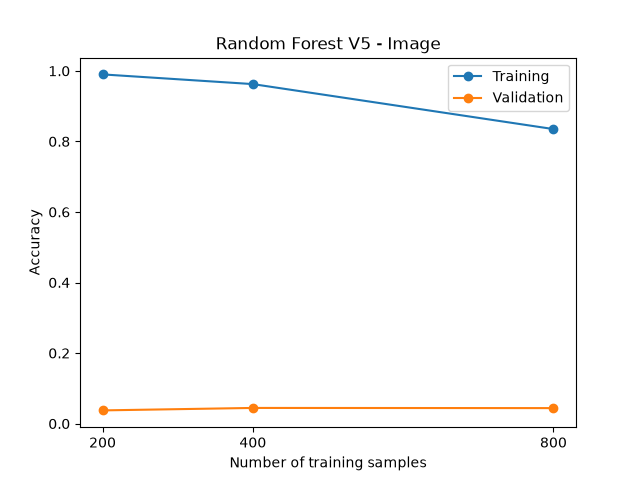

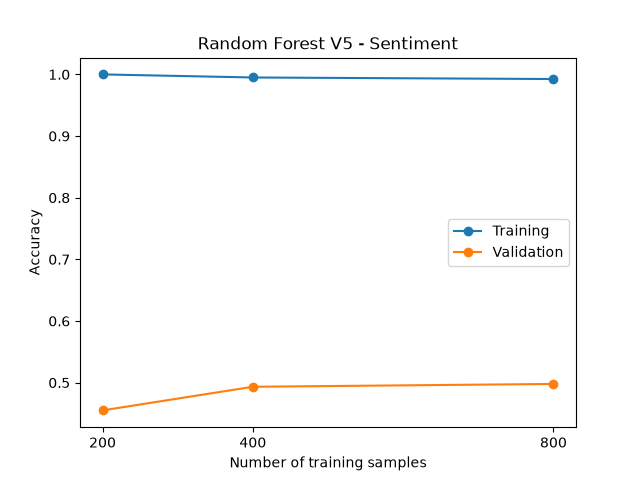

In [4]:
for task, rows in [("image", image_rows), ("sentiment", sentiment_rows)]:
    frame = pd.DataFrame(rows)
    plt.figure()
    plt.plot(frame.training_samples, frame.training_accuracy, marker="o", label="Training")
    plt.plot(frame.training_samples, frame.validation_accuracy, marker="o", label="Validation")
    plt.xlabel("Number of training samples")
    plt.ylabel("Accuracy")
    plt.title(f"Random Forest V5 - {task.capitalize()}")
    plt.xticks(training_sizes)
    plt.legend()
    plt.savefig(result_dir / f"random_forest_v5_{task}_training_size.png")
    plt.show()


Finally, I selected the best training size for each dataset using validation accuracy and saved its predictions. If accuracies tie, I keep the smaller training size.

In [5]:
summary = pd.DataFrame(summary_rows)
assert len(summary) == 6
summary.to_csv(result_dir / "random_forest_v5_summary.csv", index=False)
for task, rows, actual, prediction_map in [
    ("image", image_rows, image_actual, image_predictions),
    ("sentiment", sentiment_rows, sentiment_actual, sentiment_predictions),
]:
    best = rows[0]
    for row in rows[1:]:
        if row["validation_accuracy"] > best["validation_accuracy"]:
            best = row
    selected[task] = best
    path = result_dir / f"random_forest_v5_{task}_validation.csv"
    pd.DataFrame({"validation_index": range(len(actual)), "actual_label": actual,
                  "predicted_label": prediction_map[best["training_samples"]]}).to_csv(path, index=False)
    saved = pd.read_csv(path)
    assert saved.shape == (len(actual), 3) and not saved.isna().any().any()
    assert saved.validation_index.tolist() == list(range(len(actual)))
    assert saved.actual_label.tolist() == actual.tolist()
    assert saved.predicted_label.tolist() == prediction_map[best["training_samples"]]
    assert sum(saved.actual_label == saved.predicted_label)/len(actual) == best["validation_accuracy"]
    print(f"{task}: selected training size={best['training_samples']}, validation={best['validation_accuracy']:.2%}")
print(summary.to_string(index=False))
tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker.version.is_unique
previous_rows = tracker.loc[tracker.version != "V5"].to_dict("records")
v5_row = {"version": "V5", "image_validation_accuracy": selected["image"]["validation_accuracy"],
    "sentiment_validation_accuracy": selected["sentiment"]["validation_accuracy"],
    "kaggle_public_score": "", "submitted_to_kaggle": False, "submission_filename": "",
    "notes": f"Tested 200,400,800 training samples; selected image={selected['image']['training_samples']}, sentiment={selected['sentiment']['training_samples']}; 20 trees, depth=8 and sqrt each; min_samples=1; entropy; seed=42; original features; full validation: 4000 image/2400 sentiment. No Kaggle candidate."}
matching = tracker.version == "V5"
if matching.any():
    for col in ("image_validation_accuracy", "sentiment_validation_accuracy", "notes"):
        tracker.loc[matching, col] = str(v5_row[col])
else:
    tracker = pd.concat([tracker, pd.DataFrame([v5_row])], ignore_index=True)
assert tracker.version.is_unique
assert tracker.loc[tracker.version != "V5"].to_dict("records") == previous_rows
tracker.to_csv(tracker_path, index=False)


image: selected training size=400, validation=4.45%
sentiment: selected training size=800, validation=49.79%
  dataset version  n_trees  max_depth  min_samples n_features criterion  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  oob_accuracy  fit_time_seconds  prediction_time_seconds
    image      V5       20          8            1       sqrt   entropy       False               200                4000             0.9900             0.037500       0.04000          0.868781                 0.059913
    image      V5       20          8            1       sqrt   entropy       False               400                4000             0.9625             0.044500       0.02000          2.980698                 0.061968
    image      V5       20          8            1       sqrt   entropy       False               800                4000             0.8350             0.044000       0.04000         11.423635                 0.064266
sentiment      

I selected 400 training samples for image (4.45% full-validation accuracy) and 800 for sentiment (49.79%). V4 used only 200 validation examples, so its reported accuracy is not directly comparable to these full-validation scores.

I also compared the saved Decision Tree V5 results at the same training sizes and full validation sets. The forest uses depth 8, while the earlier trees use depths 2 and 3, so this comparison changes depth as well as the model.

In [6]:
dt_summary = pd.read_csv(project_root / "results/decision_tree/decision_tree_v5_summary.csv")
for row in summary_rows:
    dt = dt_summary.loc[(dt_summary.dataset == row["dataset"]) & (dt_summary.training_samples == row["training_samples"])].iloc[0]
    assert dt.validation_samples == row["validation_samples"]
    print(f"{row['dataset']}, {row['training_samples']} training: RF={row['validation_accuracy']:.2%}, DT={dt.validation_accuracy:.2%}; RF depth={row['max_depth']}, DT depth={dt.max_depth}")


image, 200 training: RF=3.75%, DT=3.05%; RF depth=8, DT depth=2
image, 400 training: RF=4.45%, DT=2.77%; RF depth=8, DT depth=2
image, 800 training: RF=4.40%, DT=4.10%; RF depth=8, DT depth=2
sentiment, 200 training: RF=45.50%, DT=41.12%; RF depth=8, DT depth=3
sentiment, 400 training: RF=49.33%, DT=39.75%; RF depth=8, DT depth=3
sentiment, 800 training: RF=49.79%, DT=41.38%; RF depth=8, DT depth=3
